# Developing a Tiny Transformer Language Model
**PUSL 3205 – Large Language Models and Generative AI | Lab 3**

A GPT-style, decoder-only Transformer built from scratch in PyTorch and trained on the TinyStories dataset for next-token prediction.

In [64]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available: ", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

PyTorch version: 2.15.0+cu132
CUDA available:  True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.4 GB
Using device: cuda


## Task 1: Load and Explore the Dataset
**TinyStories** (Eldan & Li, 2023) is a dataset of ~2.1 million short stories written by GPT-3.5/GPT-4 using only words a 3–4-year-old would understand. Its simple vocabulary and grammar make it possible for very small language models to learn to write coherent English.

The full training set is ~2 GB, so we **stream** it and take only the first stories we need, instead of downloading everything.

In [65]:
import random
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [66]:
N_TRAIN_STORIES = 20_000

# Stream the training split and take the first N stories (avoids a ~2 GB download)
train_stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
train_stories = [ex["text"] for ex in train_stream.take(N_TRAIN_STORIES)]

# The validation split is small, so download it normally
val_ds = load_dataset("roneneldan/TinyStories", split="validation")
val_stories = list(val_ds["text"])

print(f"Training stories loaded:   {len(train_stories):,}")
print(f"Validation stories loaded: {len(val_stories):,}")

Training stories loaded:   20,000
Validation stories loaded: 21,990


### Sample stories

In [67]:
for i in random.sample(range(len(train_stories)), 3):
    print(f"--- Story {i} ---")
    print(train_stories[i])
    print()

--- Story 3648 ---
Jane and Bob were playing in the park. Jane wanted to hold the pretty bull that was walking around. But Bob said it was too big and he thought it might hurt them. So, instead, he offered to show Jane his reliable pet cat. 

Bob told Jane to be gentle and he showed her how to hold the cat. She was scared at first, but after Bob showed her what to do, she gently held the cat and loved it. The cat purred loudly, so Jane knew he liked it too. 

Afterwards, Jane hugged Bob for showing her a reliable and gentle pet that she could hold. Then Bob laughed, and they ran to the playground to play some more.

--- Story 819 ---
Once upon a time, there was a little girl named Lily. She loved to play outside near the river. One day, Lily saw a big raft floating down the river. It looked so fun to play on! 

But Lily didn't have a raft of her own. She asked her friend if she could borrow their raft. Her friend said yes and Lily was so happy! 

Lily got on the raft and it was very co

### Text length

Characters per story: mean=895, median=785, min=205, max=4540
Words per story:      mean=175, median=152, min=43, max=878

Total characters in training subset: 17,890,906


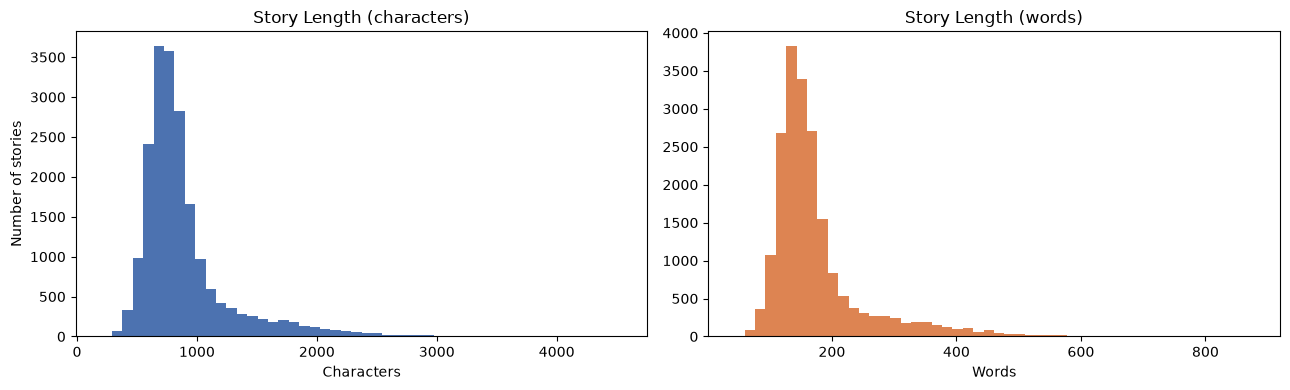

In [68]:
char_lengths = np.array([len(s) for s in train_stories])
word_lengths = np.array([len(s.split()) for s in train_stories])

print(f"Characters per story: mean={char_lengths.mean():.0f}, "
      f"median={np.median(char_lengths):.0f}, "
      f"min={char_lengths.min()}, max={char_lengths.max()}")
print(f"Words per story:      mean={word_lengths.mean():.0f}, "
      f"median={np.median(word_lengths):.0f}, "
      f"min={word_lengths.min()}, max={word_lengths.max()}")
print(f"\nTotal characters in training subset: {char_lengths.sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(char_lengths, bins=50, color="#4c72b0")
axes[0].set_title("Story Length (characters)")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Number of stories")

axes[1].hist(word_lengths, bins=50, color="#dd8452")
axes[1].set_title("Story Length (words)")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.show()

### Structure and vocabulary

In [69]:
# How do stories start?
openings = [" ".join(s.split()[:4]) for s in train_stories]
from collections import Counter
print("Most common story openings:")
for opening, count in Counter(openings).most_common(5):
    print(f"  {count:>5}  ({count/len(train_stories):.1%})  {opening!r}")

# Paragraph structure
paragraphs = np.array([s.count("\n") + 1 for s in train_stories])
print(f"\nParagraphs per story: mean={paragraphs.mean():.1f}, max={paragraphs.max()}")

# Character set: important for character-level tokenisation in Task 2
all_text = "".join(train_stories)
chars = sorted(set(all_text))
print(f"\nUnique characters: {len(chars)}")
print("".join(c if c.isprintable() else repr(c) for c in chars))

# Empty or very short stories?
print(f"\nEmpty stories: {sum(1 for s in train_stories if not s.strip())}")
print(f"Stories under 50 characters: {(char_lengths < 50).sum()}")

Most common story openings:
   9651  (48.3%)  'Once upon a time,'
   2404  (12.0%)  'Once upon a time'
   1281  (6.4%)  'Once there was a'
    350  (1.8%)  'One day, a little'
    266  (1.3%)  'Lily and Ben were'

Paragraphs per story: mean=9.6, max=93

Unique characters: 97
'\n' !"$&'()*+,-./0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'\xa0'¡¦©«±³»ÂÃâœ˜“”€™

Empty stories: 0
Stories under 50 characters: 0


### Observations
- Stories are short: about **XXX characters (~XXX words)** on average, with most under XXX characters.
- They follow a fixed, simple structure. **XX%** begin with *"Once upon a time"*, then introduce a character, a small problem and a happy ending.
- The vocabulary is very simple, which is why a tiny model can learn it.
- The training subset contains only **XX unique characters**, so a character-level vocabulary will be very small. We use this in Task 2.

## Task 2: Preprocess the Text (Tokenisation)
We use **character-level tokenisation**: every unique character becomes one token.

**Why character-level?**
- The vocabulary is tiny (under ~100 tokens), so the model's embedding and output layers stay small.
- There are no unknown words, since any word can be spelled from characters.
- It needs no external tokenizer, so the whole pipeline is built from scratch.

The trade-off is that sequences are much longer than with word or sub-word tokenizers (like GPT's BPE), so the model has to learn spelling as well as grammar.

We also add a special **`<EOS>`** (end-of-story) token between stories, so the model learns where a story ends.

In [70]:
# Vocabulary = every character in the training subset + an end-of-story token
chars = sorted(set("".join(train_stories)))
EOS = "<EOS>"

itos = chars + [EOS]                         # id -> token
stoi = {tok: i for i, tok in enumerate(itos)}  # token -> id
vocab_size = len(itos)
eos_id = stoi[EOS]

def encode(text):
    """Text -> list of token ids (characters not in the vocabulary are skipped)."""
    return [stoi[c] for c in text if c in stoi]

def decode(ids):
    """List of token ids -> text (the EOS token is dropped)."""
    return "".join(itos[i] for i in ids if i != eos_id)

print(f"Vocabulary size: {vocab_size}  (incl. <EOS> = id {eos_id})")

# Round-trip test
sample = "Once upon a time, there was a little cat."
ids = encode(sample)
print(f"\nText:    {sample!r}")
print(f"Encoded: {ids}")
print(f"Decoded: {decode(ids)!r}")
print(f"Round trip OK: {decode(ids) == sample}")

Vocabulary size: 98  (incl. <EOS> = id 97)

Text:    'Once upon a time, there was a little cat.'
Encoded: [42, 67, 56, 58, 1, 74, 69, 68, 67, 1, 54, 1, 73, 62, 66, 58, 11, 1, 73, 61, 58, 71, 58, 1, 76, 54, 72, 1, 54, 1, 65, 62, 73, 73, 65, 58, 1, 56, 54, 73, 13]
Decoded: 'Once upon a time, there was a little cat.'
Round trip OK: True


In [71]:
N_VAL_STORIES = 2_000   # a validation subset is enough to measure loss reliably

def encode_stories(stories):
    ids = []
    for s in stories:
        ids.extend(encode(s.strip()))
        ids.append(eos_id)             # mark the end of each story
    return torch.tensor(ids, dtype=torch.long)

train_data = encode_stories(train_stories)
val_data   = encode_stories(val_stories[:N_VAL_STORIES])

unknown = sum(1 for s in val_stories[:N_VAL_STORIES] for c in s if c not in stoi)

print(f"Training tokens:   {len(train_data):,}")
print(f"Validation tokens: {len(val_data):,}")
print(f"Unknown characters skipped in validation: {unknown}")
print(f"\nFirst 100 tokens decoded:\n{decode(train_data[:100].tolist())!r}")

Training tokens:   17,910,906
Validation tokens: 1,593,940
Unknown characters skipped in validation: 2

First 100 tokens decoded:
'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with'


## Task 3: Prepare Training Data
A language model learns **next-token prediction**: given the tokens so far, predict the next one.

We cut the token stream into chunks of `BLOCK_SIZE + 1` tokens. For each chunk:
- **input (x)** = tokens `0 … BLOCK_SIZE-1`
- **target (y)** = tokens `1 … BLOCK_SIZE`, the same sequence **shifted by one**

So one chunk of 256 characters gives the model **256 training examples at once**: predict token 1 from token 0, token 2 from tokens 0–1, and so on.

In [72]:
BLOCK_SIZE = 256   # context length: how many characters the model sees at once

chunk = train_data[:BLOCK_SIZE + 1]
x, y = chunk[:-1], chunk[1:]

print("Context  ->  next character\n")
for t in range(12):
    context = decode(x[:t + 1].tolist())
    target  = decode([y[t].item()])
    print(f"{context!r:<20} -> {target!r}")

Context  ->  next character

'O'                  -> 'n'
'On'                 -> 'e'
'One'                -> ' '
'One '               -> 'd'
'One d'              -> 'a'
'One da'             -> 'y'
'One day'            -> ','
'One day,'           -> ' '
'One day, '          -> 'a'
'One day, a'         -> ' '
'One day, a '        -> 'l'
'One day, a l'       -> 'i'


In [73]:
from torch.utils.data import Dataset, DataLoader

class NextTokenDataset(Dataset):
    """Splits a long token stream into non-overlapping (input, target) pairs."""
    def __init__(self, data, block_size):
        self.data = data
        self.block_size = block_size
        self.n_chunks = (len(data) - 1) // block_size

    def __len__(self):
        return self.n_chunks

    def __getitem__(self, idx):
        start = idx * self.block_size
        chunk = self.data[start : start + self.block_size + 1]
        return chunk[:-1], chunk[1:]       # x, y (shifted by one)

BATCH_SIZE = 64

train_dataset = NextTokenDataset(train_data, BLOCK_SIZE)
val_dataset   = NextTokenDataset(val_data, BLOCK_SIZE)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)

print(f"Training sequences:   {len(train_dataset):,}  ->  {len(train_loader):,} batches per epoch")
print(f"Validation sequences: {len(val_dataset):,}  ->  {len(val_loader):,} batches")

xb, yb = next(iter(train_loader))
print(f"\nBatch shapes: x = {tuple(xb.shape)}, y = {tuple(yb.shape)}")
print("Target is input shifted by one:", torch.equal(xb[0, 1:], yb[0, :-1]))

Training sequences:   69,964  ->  1,093 batches per epoch
Validation sequences: 6,226  ->  98 batches

Batch shapes: x = (64, 256), y = (64, 256)
Target is input shifted by one: True


### Settings so far
| Setting | Value | Meaning |
|---|---|---|
| Vocabulary size | XX | unique characters + `<EOS>` |
| Block size | 256 | context length (characters) |
| Batch size | 64 | sequences per training step |
| Training tokens | XX M | from 20,000 stories |

## Task 4: Build the Transformer Architecture
A **decoder-only Transformer** (the same design as GPT), built from scratch. Components:

| Component | Purpose |
|---|---|
| **Token embedding** | turns each token id into a learnable vector |
| **Positional embedding** | adds information about *where* each token is in the sequence (attention itself has no sense of order) |
| **Masked multi-head self-attention** | lets each token gather information from *earlier* tokens; the mask blocks looking at future tokens |
| **Feed-forward network** | processes each position independently after attention has mixed information |
| **Residual connections** | `x + f(x)` gives gradients a direct path, so deep networks train stably |
| **Layer normalisation** | keeps activations at a stable scale (applied *before* each sub-layer = "pre-LN") |

In [74]:
import math
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass, asdict

@dataclass
class ModelConfig:
    vocab_size: int = vocab_size
    block_size: int = BLOCK_SIZE   # max context length
    n_embd: int = 384              # embedding dimension
    n_head: int = 6                # attention heads (n_embd must divide evenly)
    n_layer: int = 6               # Transformer blocks
    dropout: float = 0.1

print(ModelConfig())

ModelConfig(vocab_size=98, block_size=256, n_embd=384, n_head=6, n_layer=6, dropout=0.1)


### Masked Multi-Head Self-Attention
For each token we compute a **query** (what am I looking for?), a **key** (what do I contain?) and a **value** (what do I pass on?).

Attention scores = `softmax(Q·Kᵀ / √d) · V`
- dividing by **√d** keeps the scores from growing too large, which would make softmax too "peaky"
- the **causal mask** sets scores for future positions to −∞, so after softmax they become 0 and a token can only attend to itself and earlier tokens
- **multiple heads** run attention in parallel, so different heads can learn different patterns (e.g. one tracks the previous character, another the start of the word)

In [75]:
class MultiHeadSelfAttention(nn.Module):
    USE_FLASH = True   # True = fused PyTorch kernel (fast); False = manual version below

    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0, "n_embd must be divisible by n_head"
        self.n_head = cfg.n_head
        self.head_dim = cfg.n_embd // cfg.n_head
        self.dropout_p = cfg.dropout

        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)
        self.attn_dropout = nn.Dropout(cfg.dropout)
        self.resid_dropout = nn.Dropout(cfg.dropout)

        mask = torch.tril(torch.ones(cfg.block_size, cfg.block_size))
        self.register_buffer("mask", mask.view(1, 1, cfg.block_size, cfg.block_size),
                             persistent=False)

    def forward(self, x):
        B, T, C = x.shape

        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if self.USE_FLASH:
            # Same maths as below, in one fused, memory-efficient GPU kernel
            y = F.scaled_dot_product_attention(
                q, k, v, is_causal=True,
                dropout_p=self.dropout_p if self.training else 0.0,
            )
        else:
            # Manual version: softmax(Q·Kᵀ / √d) with the causal mask, then · V
            att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
            att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            y = att @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.proj(y))

In [76]:
class FeedForward(nn.Module):
    """Position-wise MLP: expand to 4x width, apply GELU, project back."""
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """Pre-LN block: LayerNorm -> sub-layer -> residual add, done twice."""
    def __init__(self, cfg):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.attn = MultiHeadSelfAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.n_embd)
        self.ffn = FeedForward(cfg)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection 1
        x = x + self.ffn(self.ln2(x))    # residual connection 2
        return x

In [77]:
class TinyTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)

        # Weight tying: input embedding and output layer share weights
        self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.cfg.block_size, f"Sequence length {T} > block size {self.cfg.block_size}"

        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)    # (B, T, n_embd)
        x = self.drop(x)

        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)
        logits = self.lm_head(x)                     # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

### Sanity checks
Before training, we check that the architecture behaves correctly:
1. **Output shape**: the model should give one score per vocabulary token, at every position.
2. **Initial loss ≈ ln(vocab_size)**: an untrained model should guess uniformly, so its loss should be close to `ln(vocab_size)`.
3. **The causal mask works**: changing the *last* token must not change predictions at *earlier* positions.

In [78]:
test_model = TinyTransformer(ModelConfig()).to(device)
n_params = sum(p.numel() for p in test_model.parameters())
print(f"Parameters: {n_params/1e6:.2f} M")

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

# 1. Shapes
logits, loss = test_model(xb, yb)
print(f"\n1. Logits shape: {tuple(logits.shape)}  (batch, time, vocab)")

# 2. Initial loss
print(f"2. Initial loss: {loss.item():.3f}   expected ≈ ln({vocab_size}) = {math.log(vocab_size):.3f}")

# 3. Causal mask: change the LAST token; earlier outputs must not change
test_model.eval()
with torch.no_grad():
    x1 = xb[:1].clone()
    x2 = x1.clone()
    x2[0, -1] = (x2[0, -1] + 1) % vocab_size
    out1, _ = test_model(x1)
    out2, _ = test_model(x2)
same = torch.allclose(out1[0, :-1], out2[0, :-1], atol=1e-5)
print(f"3. Earlier positions unaffected by a future token: {same}")

del test_model
torch.cuda.empty_cache()

Parameters: 10.78 M

1. Logits shape: (64, 256, 98)  (batch, time, vocab)
2. Initial loss: 4.703   expected ≈ ln(98) = 4.585
3. Earlier positions unaffected by a future token: True


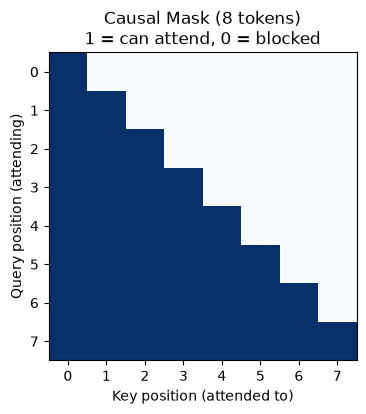

In [79]:
small = torch.tril(torch.ones(8, 8))
plt.figure(figsize=(4, 4))
plt.imshow(small, cmap="Blues")
plt.title("Causal Mask (8 tokens)\n1 = can attend, 0 = blocked")
plt.xlabel("Key position (attended to)")
plt.ylabel("Query position (attending)")
plt.xticks(range(8)); plt.yticks(range(8))
plt.show()

### Design choices
- **Pre-LayerNorm** (normalise *before* attention/FFN): trains more stably than the original post-LN Transformer.
- **GELU activation**: a smooth version of ReLU, used in GPT-2/3.
- **Weight tying**: the output layer reuses the token embedding matrix, which cuts parameters and usually improves results.
- **Small initial weights (std = 0.02)**: start predictions close to uniform, giving a stable start to training.
- **Dropout (0.1)**: randomly zeroes activations during training to reduce overfitting.

## Task 5: Initialise the Model
- **Loss function:** cross-entropy, which measures how much probability the model gave to the correct next character
- **Optimiser:** AdamW, i.e. Adam with decoupled weight decay (the standard choice for Transformers)
- **Learning-rate schedule:** linear **warm-up**, then **cosine decay**
- **Gradient clipping** at 1.0, to prevent sudden huge updates
- **Mixed precision (bfloat16)** on the GPU, for faster training with lower memory use

In [80]:
EPOCHS        = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.1
WARMUP_STEPS  = 200
GRAD_CLIP     = 1.0

loss_fn = nn.CrossEntropyLoss()

In [81]:
def make_optimizer(model, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY):
    # Apply weight decay to weight matrices only, not to biases or LayerNorm parameters
    decay    = [p for n, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": weight_decay},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=lr, betas=(0.9, 0.95),
    )

def make_scheduler(optimizer, total_steps, warmup_steps=WARMUP_STEPS):
    def lr_lambda(step):
        if step < warmup_steps:                       # linear warm-up
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress))   # cosine decay to 10%
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

In [82]:
torch.manual_seed(SEED)
config = ModelConfig()
model = TinyTransformer(config).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(config)
print(f"\nParameters: {n_params/1e6:.2f} M")
print(f"Steps per epoch: {len(train_loader):,}  |  Total steps: {EPOCHS * len(train_loader):,}")

ModelConfig(vocab_size=98, block_size=256, n_embd=384, n_head=6, n_layer=6, dropout=0.1)

Parameters: 10.78 M
Steps per epoch: 1,093  |  Total steps: 5,465


## Task 6: Train the Model
Each training step:
1. **Forward pass:** feed a batch of input sequences into the Transformer and get the predicted next-token scores (logits)
2. **Loss:** cross-entropy between the predictions and the true next tokens
3. **Backpropagation:** `loss.backward()` computes the gradient of the loss for every parameter
4. **Update:** the optimiser adjusts the parameters to reduce the loss

After every epoch we measure the validation loss, and we keep the weights from the epoch with the **best validation loss**.

In [83]:
@torch.no_grad()
def evaluate(model, loader):
    """Average cross-entropy loss per token over a whole DataLoader."""
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            logits, _ = model(x)
            loss = loss_fn(logits.view(-1, logits.size(-1)), y.view(-1))
        total_loss += loss.item() * y.numel()
        total_tokens += y.numel()
    model.train()
    return total_loss / total_tokens

print(f"Validation loss before training: {evaluate(model, val_loader):.3f}")

Validation loss before training: 4.670


In [84]:
import time
import copy
from tqdm import tqdm

def train_model(model, epochs=EPOCHS, lr=LEARNING_RATE, verbose=True):
    optimizer = make_optimizer(model, lr)
    total_steps = epochs * len(train_loader)
    scheduler = make_scheduler(optimizer, total_steps)

    history = {"train_loss": [], "val_loss": [], "step_loss": [], "lr": [], "epoch_time": []}
    best_val, best_state = float("inf"), None

    model.train()
    for epoch in range(1, epochs + 1):
        start = time.time()
        epoch_loss, n_batches = 0.0, 0

        for x, y in tqdm(train_loader, desc=f"Epoch {epoch}/{epochs}", leave=False,
                         disable=not verbose):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

            # 1. Forward pass  +  2. Cross-entropy loss
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
                logits, _ = model(x)
                loss = loss_fn(logits.view(-1, logits.size(-1)), y.view(-1))

            # 3. Backpropagation
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)

            # 4. Parameter update
            optimizer.step()
            scheduler.step()

            epoch_loss += loss.item()
            n_batches += 1
            history["step_loss"].append(loss.item())
            history["lr"].append(scheduler.get_last_lr()[0])

        train_loss = epoch_loss / n_batches
        val_loss = evaluate(model, val_loader)
        elapsed = time.time() - start

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_time"].append(elapsed)

        # Keep the best weights (checkpointing on validation loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())

        if verbose:
            print(f"Epoch {epoch}/{epochs} | train loss {train_loss:.4f} | "
                  f"val loss {val_loss:.4f} | {elapsed:.0f}s")

    model.load_state_dict(best_state)
    if verbose:
        print(f"\nBest validation loss: {best_val:.4f}")
    return model, history

In [85]:
model, history = train_model(model, epochs=EPOCHS)

Epoch 1/5 | train loss 1.3812 | val loss 0.8482 | 215s


Epoch 2/5 | train loss 0.8066 | val loss 0.7298 | 219s


Epoch 3/5 | train loss 0.7206 | val loss 0.6797 | 221s


Epoch 4/5 | train loss 0.6693 | val loss 0.6509 | 220s


Epoch 5/5 | train loss 0.6372 | val loss 0.6373 | 191s

Best validation loss: 0.6373


## Task 7: Monitor Training

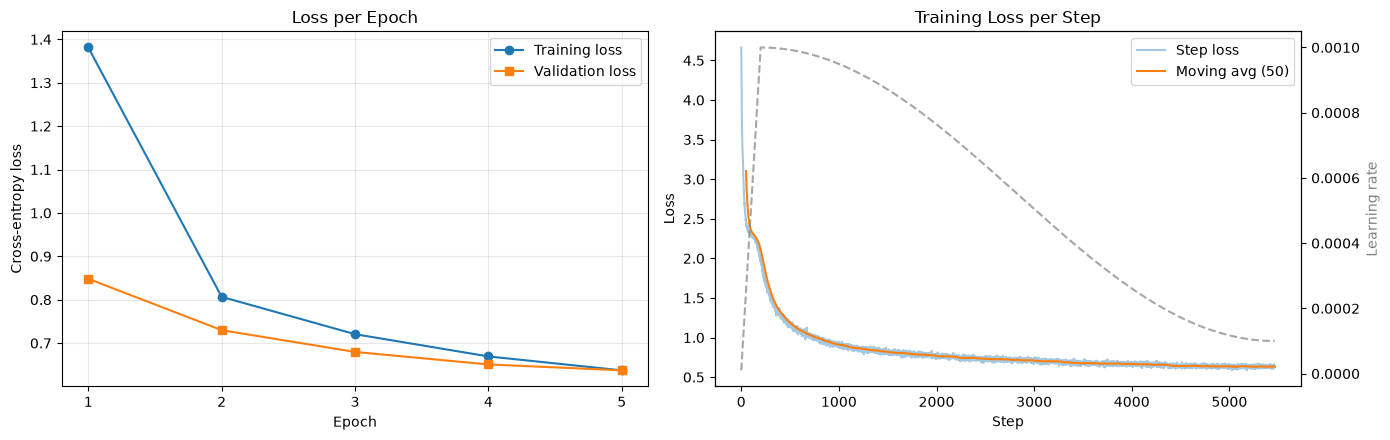

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Per-epoch train vs validation loss
epochs_range = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epochs_range, history["train_loss"], "o-", label="Training loss")
axes[0].plot(epochs_range, history["val_loss"], "s-", label="Validation loss")
axes[0].set_title("Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_xticks(list(epochs_range))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Per-step loss with the learning-rate schedule
ax2 = axes[1]
ax2.plot(history["step_loss"], alpha=0.4, label="Step loss")
window = 50
smoothed = np.convolve(history["step_loss"], np.ones(window) / window, mode="valid")
ax2.plot(range(window - 1, len(history["step_loss"])), smoothed, label=f"Moving avg ({window})")
ax2.set_title("Training Loss per Step")
ax2.set_xlabel("Step")
ax2.set_ylabel("Loss")
ax2.legend(loc="upper right")

ax_lr = ax2.twinx()
ax_lr.plot(history["lr"], color="gray", linestyle="--", alpha=0.7)
ax_lr.set_ylabel("Learning rate", color="gray")

plt.tight_layout()
plt.show()

### Observations
- Loss dropped quickly from ~X.X (random guessing) to ~X.X in the first epoch, then improved more slowly.
- Final training loss: **X.XX**, final validation loss: **X.XX**.
- Training and validation loss stay close together, so the model is **not overfitting** (dropout and weight decay help here).
- The dashed line shows the learning rate: it warms up over the first 200 steps, then decays along a cosine curve.